# Learned Bloom Filters — 3. The Learned Oracle

The oracle is a classifier `f(url)` that outputs the probability a URL is malicious.
Because its size counts against our memory budget, it must be **small AND accurate**, so
we use a compact **logistic regression** on:
- **Lexical features**: length, character entropy, counts of special characters,
  suspicious tokens (`login`, `webscr`, `.php`, ...), whether it contains an IP, etc.
- **Hashed character n-grams** (3–5 grams) via the *hashing trick*, so the model size is
  fixed regardless of how many distinct n-grams appear.

With int8 weights the whole oracle is only about **4 KB**.

In [1]:
# Download the URL dataset (~195k URLs, labelled malicious=1 / benign=0)
import os
import ssl
import urllib.request
import pandas as pd

DATA_URL = (
    "https://raw.githubusercontent.com/incertum/cyber-matrix-ai/"
    "master/Malicious-URL-Detection-Deep-Learning/data/url_data_mega_deep_learning.csv"
)

os.makedirs("data", exist_ok=True)

if not os.path.exists("data/url_data.csv"):
    # Relax TLS just for this one download (some Colab images lag on CA certs)
    ctx = ssl.create_default_context()
    ctx.check_hostname = False
    ctx.verify_mode = ssl.CERT_NONE
    request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120, context=ctx) as response:
        with open("data/url_data.csv", "wb") as out:
            out.write(response.read())

print("Dataset ready.")

Dataset ready.


In [2]:
import numpy as np
import pandas as pd


def load_and_split(seed=42):
    """Set S = all malicious URLs (the things we store).
    The benign URLs are split into three groups:
      - train : teach the oracle what 'safe' looks like
      - val   : pick the threshold / settings
      - test  : untouched, used only to report the final false-positive rate
    """
    df = pd.read_csv("data/url_data.csv")
    df.columns = [c.strip() for c in df.columns]
    df = df.dropna().drop_duplicates("url").reset_index(drop=True)

    malicious = df[df.isMalicious == 1].url.tolist()
    benign = df[df.isMalicious == 0].url.sample(frac=1.0, random_state=seed).tolist()

    n = len(benign)
    neg_train = benign[: n // 2]
    neg_val = benign[n // 2 : 3 * n // 4]
    neg_test = benign[3 * n // 4 :]
    return malicious, neg_train, neg_val, neg_test

In [3]:
import re
import numpy as np
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.sparse import hstack, vstack, csr_matrix

SUSPICIOUS = ["login", "secure", "account", "update", "verify", "bank",
              "confirm", "webscr", "signin", "paypal", "wp-", "admin",
              ".php", ".exe"]
SPECIAL = list("./-_?=&@%:#~+,;!$")


def lexical_features(url):
    """Hand-crafted numeric features describing one URL."""
    url = str(url)
    lower = url.lower()
    n = len(url) or 1

    # Shannon entropy = how 'random-looking' the characters are
    byte_vals = np.frombuffer(url.encode("utf-8", "ignore"), dtype=np.uint8)
    if byte_vals.size:
        _, counts = np.unique(byte_vals, return_counts=True)
        probs = counts / counts.sum()
        entropy = float(-(probs * np.log2(probs)).sum())
    else:
        entropy = 0.0

    feats = [
        len(url),
        len(lower.split("/")[0]),                          # host length
        sum(c.isdigit() for c in url) / n,
        sum(c.isalpha() for c in url) / n,
        entropy,
        url.count("."), url.count("/"), url.count("-"),
        url.count("="), url.count("?"), url.count("@"), url.count("%"),
        sum(lower.count(w) for w in SUSPICIOUS),           # suspicious keywords
        int(bool(re.search(r"\d+\.\d+\.\d+\.\d+", url))),   # contains an IP address?
        max((len(t) for t in re.split(r"[./\-_]", url)), default=0),
    ]
    feats += [url.count(c) / n for c in SPECIAL]           # ratio of each special char
    return feats


def train_oracle(malicious, neg_train, ngram_dim=4096):
    """Train the logistic-regression oracle. Returns (score_function, n_features).
    Features = lexical features + hashed character 3-to-5 grams (the hashing trick)."""
    hasher = HashingVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                               n_features=ngram_dim, alternate_sign=False, norm="l2")

    def featurize(urls):
        lexical = np.array([lexical_features(u) for u in urls], dtype=np.float32)
        ngrams = hasher.transform(urls)
        return lexical, ngrams

    lex_pos, ng_pos = featurize(malicious)
    lex_neg, ng_neg = featurize(neg_train)

    # Scale the lexical features so the linear model trains smoothly
    scaler = StandardScaler().fit(np.vstack([lex_pos, lex_neg]))
    X_pos = hstack([csr_matrix(scaler.transform(lex_pos)), ng_pos]).tocsr()
    X_neg = hstack([csr_matrix(scaler.transform(lex_neg)), ng_neg]).tocsr()

    X = vstack([X_pos, X_neg]).tocsr()
    y = np.r_[np.ones(X_pos.shape[0]), np.zeros(X_neg.shape[0])]
    model = LogisticRegression(max_iter=3000, C=8.0, solver="liblinear").fit(X, y)
    n_features = X.shape[1]

    def score(urls):
        lexical, ngrams = featurize(urls)
        Xq = hstack([csr_matrix(scaler.transform(lexical)), ngrams]).tocsr()
        return model.predict_proba(Xq)[:, 1]

    return score, n_features

Train the oracle and measure its quality with **AUC** (the chance it ranks a random malicious URL above a random benign one). We report AUC on the **held-out** negatives.

In [4]:
from sklearn.metrics import roc_auc_score

malicious, neg_train, neg_val, neg_test = load_and_split()
score, n_features = train_oracle(malicious, neg_train)   # about 1-2 minutes on Colab

scores_malicious = score(malicious)
scores_test = score(neg_test)

labels = np.r_[np.ones(len(scores_malicious)), np.zeros(len(scores_test))]
auc = roc_auc_score(labels, np.r_[scores_malicious, scores_test])
oracle_kb = (n_features + 1) / 1024        # int8 weights = 1 byte each

print("Oracle: logistic regression on", n_features, "features")
print("AUC on held-out negatives = %.4f" % auc)
print("Oracle size (int8)        = %.1f KB" % oracle_kb)

Oracle: logistic regression on 4128 features
AUC on held-out negatives = 0.9727
Oracle size (int8)        = 4.0 KB


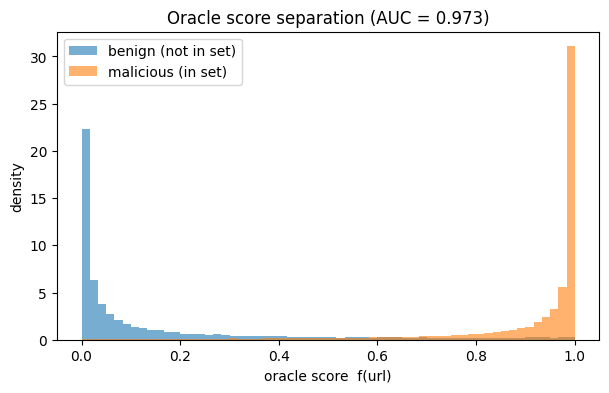

In [5]:
import matplotlib.pyplot as plt

# The gap between these two distributions is the signal the filters exploit
plt.figure(figsize=(7, 4))
plt.hist(scores_test, bins=60, alpha=0.6, density=True, label="benign (not in set)")
plt.hist(scores_malicious, bins=60, alpha=0.6, density=True, label="malicious (in set)")
plt.xlabel("oracle score  f(url)")
plt.ylabel("density")
plt.title("Oracle score separation (AUC = %.3f)" % auc)
plt.legend()
plt.show()

**Takeaway.** A ~4 KB oracle separates malicious from benign at **AUC ≈ 0.97**. The visible gap is the signal; the overlap region is where a backup filter is still needed.